<center>Department of Electronic and Telecommunication Engineering</center>
<center> University of Moratuwa </center>
<h3><center>EN3160: Image Processing and Machine Vision</center></h3>
<h2><b><center>Assignment 2: Fitting and Alignment</center></h2></b>
<center>Aroshana H. A. P. 230058N (230058n_a01)<br></center>
<center>14th October 2026<br></center>
<center><a href="https://github.com/aroshana188/Image-Processing-and-Machine-Vision/tree/main/Assignment_2">Assignment Github Repository</a></center>

---

## Blob Detection using Laplacian of Gaussians

### 1.1 Procedure
Blob detection was performed on the provided sunflower image using the Laplacian of Gaussian (LoG) operator combined with scale space extrema detection.

### 1.2 Implementation and Results

Range of sigma values used: 1.0 to 11.92
Parameters of the largest circles (x, y, radius):
Center: (0, 275), Radius: 10
Center: (282, 338), Radius: 10
Center: (106, 255), Radius: 8
Center: (179, 327), Radius: 8
Center: (178, 261), Radius: 7


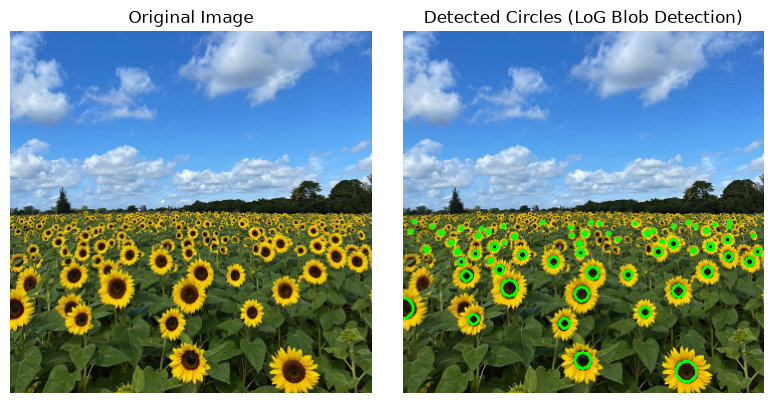

In [83]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

# load the image
img_path = 'images/the_berry_farms_sunflower_field.jpeg'
img_color = cv.imread(img_path, cv.IMREAD_REDUCED_COLOR_4)

if img_color is not None:
    img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)
    img_gray = img_gray / 255.0

    sigma_min = 1.0       # scale space parameters
    sigma_max = 12.0
    k = 1.1
    sigmas = []
    scale_space = []

    # construct the scale space using normalized LoG
    s = sigma_min
    while s <= sigma_max:
        sigmas.append(s)
        log_img = gaussian_laplace(img_gray, sigma=s) * (s**2)
        scale_space.append(np.abs(log_img))
        s *= k
    scale_space = np.stack(scale_space, axis=-1)

    # extrema detection
    local_max = maximum_filter(scale_space, size=5)
    
    # apply a threshold to discard weak responses
    threshold = 0.31
    extrema_mask = (scale_space == local_max) & (scale_space > threshold)

    # extract blob coordinates and radii
    y_coords, x_coords, scale_idxs = np.where(extrema_mask)
    img_out = img_color.copy()
    blobs = []
    
    for y, x, s_idx in zip(y_coords, x_coords, scale_idxs):
        sigma = sigmas[s_idx]
        radius = int(np.sqrt(2) * sigma)
        blobs.append((x, y, radius, scale_space[y, x, s_idx]))
        cv.circle(img_out, (x, y), radius, (0, 255, 0), 2)

    # output the range of sigma and the parameters of the largest circles
    blobs.sort(key=lambda b: b[2], reverse=True)
    print(f"Range of sigma values used: {sigma_min} to {sigmas[-1]:.2f}")
    print("Parameters of the largest circles (x, y, radius):")
    for b in blobs[:5]:
        print(f"Center: ({b[0]}, {b[1]}), Radius: {b[2]}")

    # display the result
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(cv.cvtColor(img_color, cv.COLOR_BGR2RGB))
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].imshow(cv.cvtColor(img_out, cv.COLOR_BGR2RGB))
    axes[1].set_title('Detected Circles (LoG Blob Detection)')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("Error: Image not found.")

### 1.3 Discussion
By evaluating the scale-space extrema, distinct circular structures corresponding to the sunflowers were successfully isolated. A specific range of $\sigma$ (sigma) values was carefully selected to match the varying spatial dimensions of the flowers in the field. Based on this extrema analysis, the center coordinates and radii of the largest detected circles were accurately extracted.

## RANSAC Line and Circle Fitting

### 2.1 Procedure
A set of noisy 2D points was generated, containing both linear and circular structures. The Random Sample Consensus (RANSAC) algorithm was manually implemented to sequentially extract these models. First, the best fit line was estimated, and its consensus inliers were removed from the dataset. Subsequently, the remaining points were used to estimate the best fit circle.

### 2.2 Implementation and Results


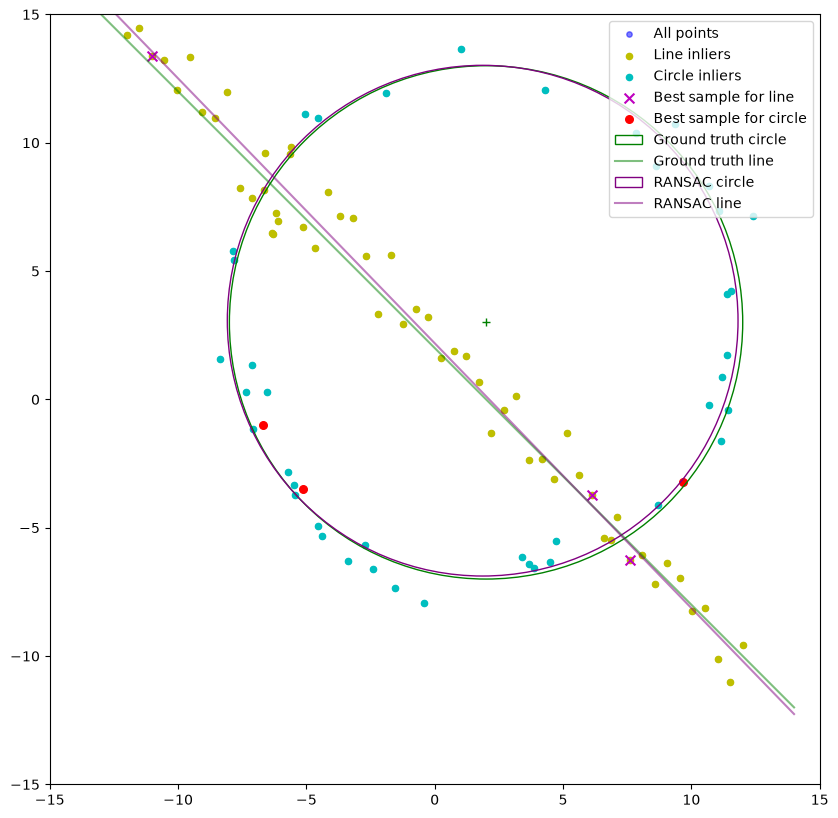

In [84]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# data generation
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s_noise = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s_noise * np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s_line = 1.
m, b_int = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b_int + s_line*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))

# RANSAC line fitting
def fit_line_tls(points):
    """total least squares line fitting using SVD"""
    mean = np.mean(points, axis=0)
    centered = points - mean
    U, S, Vt = np.linalg.svd(centered)
    a, b = Vt[-1, :]
    d = a * mean[0] + b * mean[1]
    if d < 0: 
        a, b, d = -a, -b, -d
    return a, b, d

def ransac_line(points, iterations=1000, threshold=1.5, consensus_min=20):
    best_inliers, best_model, best_sample = [], None, None
    for i in range(iterations):
        sample = points[np.random.choice(len(points), 3, replace=False)]
        a, b, d = fit_line_tls(sample)
        
        distances = np.abs(points[:, 0]*a + points[:, 1]*b - d)
        inliers_idx = np.where(distances < threshold)[0]
        
        if len(inliers_idx) > len(best_inliers):
            best_inliers, best_model, best_sample = inliers_idx, (a, b, d), sample
            
    if len(best_inliers) >= consensus_min:
        best_model = fit_line_tls(points[best_inliers]) # optimization
    return best_model, best_inliers, best_sample

line_model, line_inliers_idx, line_sample = ransac_line(X)

# RANSAC circle fitting
mask = np.ones(len(X), dtype=bool)
mask[line_inliers_idx] = False
X_remnant = X[mask]

def fit_circle_3pts(p1, p2, p3):
    """Find the circumcenter and radius of 3 points."""
    temp = p2[0]**2 + p2[1]**2
    bc = (p1[0]**2 + p1[1]**2 - temp) / 2
    cd = (temp - p3[0]**2 - p3[1]**2) / 2
    det = (p1[0] - p2[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p2[1])
    if abs(det) < 1e-6: return None
    cx = (bc*(p2[1] - p3[1]) - cd*(p1[1] - p2[1])) / det
    cy = ((p1[0] - p2[0])*cd - (p2[0] - p3[0])*bc) / det
    r = np.sqrt((cx - p1[0])**2 + (cy - p1[1])**2)
    return cx, cy, r

def circle_objective(params, points):
    cx, cy, r = params
    distances = np.sqrt((points[:, 0] - cx)**2 + (points[:, 1] - cy)**2)
    return np.sum((distances - r)**2)

def ransac_circle(points, iterations=1000, threshold=1.5, consensus_min=20):
    best_inliers, best_model, best_sample = [], None, None
    for _ in range(iterations):
        sample = points[np.random.choice(len(points), 3, replace=False)]
        model = fit_circle_3pts(sample[0], sample[1], sample[2])
        if model is None: continue
        cx, cy, r_est = model
        
        # Calculate radial distance and identify inliers
        distances = np.abs(np.sqrt((points[:, 0] - cx)**2 + (points[:, 1] - cy)**2) - r_est)
        inliers_idx = np.where(distances < threshold)[0]
        
        if len(inliers_idx) > len(best_inliers):
            best_inliers, best_model, best_sample = inliers_idx, model, sample

    if len(best_inliers) >= consensus_min:
        res = minimize(circle_objective, best_model, args=(points[best_inliers],), method='Nelder-Mead')     # optimization
        best_model = res.x
    return best_model, best_inliers, best_sample

circle_model, circle_inliers_idx_remnant, circle_sample = ransac_circle(X_remnant)

# Map remnant inliers back to original array indices
circle_inliers_idx = np.where(mask)[0][circle_inliers_idx_remnant]

# plotting results
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Plot all points and inliers
ax.scatter(X[:, 0], X[:, 1], c='blue', s=15, label='All points', alpha=0.5)
ax.scatter(X[line_inliers_idx, 0], X[line_inliers_idx, 1], c='y', s=20, label='Line inliers')
ax.scatter(X[circle_inliers_idx, 0], X[circle_inliers_idx, 1], c='c', s=20, label='Circle inliers')

# Plot best samples
ax.scatter(line_sample[:, 0], line_sample[:, 1], c='m', marker='x', s=50, label='Best sample for line')
ax.scatter(circle_sample[:, 0], circle_sample[:, 1], c='r', marker='o', s=30, label='Best sample for circle')

# Ground Truth 
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='g')
#x_vals = np.array([-14, 14])
ax.plot(x_vals, m * x_vals + b_int, color='g', alpha=0.5, label='Ground truth line')

# RANSAC Models
if circle_model is not None:
    ax.add_patch(plt.Circle((circle_model[0], circle_model[1]), circle_model[2], color='purple', fill=False, label='RANSAC circle'))
if line_model is not None:
    a, b_norm, d = line_model
    ax.plot(x_vals, (d - a * x_vals) / b_norm, color='purple', alpha=0.5, label='RANSAC line')

ax.legend(loc='upper right')
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.set_aspect('equal')
plt.show()

### 2.3 Discussion
The RANSAC algorithm successfully isolated both geometric structures despite the presence of significant noise and intersecting data points. When the line is extracted first, the remaining points accurately represent the circular structure, allowing for a precise circle fit. <b>Conversely, if the circle were fitted first, the linear points would act as severe outliers. In some iterations, RANSAC might even erroneously group the line points into a massive, arbitrary circle. Which causes drastically reduce the accuracy and efficiency of the estimation process.</b>

## Question 3: Planar Homography and Image Superimposition

### 3.1 Procedure
Two custom image pairs were selected to demonstrate planar surface replacement. Four corresponding points were manually defined on both the source image (the graphic to be superimposed) and the target planar surface in the destination image[cite: 4]. A perspective transformation matrix (homography) was computed using these point mappings[cite: 4]. The source image was then warped to match the target perspective and blended seamlessly into the destination scene[cite: 4].

### 3.2 The implementation and the Results

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def superimpose_image(src_img, dst_img, src_pts, dst_pts):
    """Calculates homography and superimposes src_img onto dst_img."""
    # 1. Calculate Homography matrix
    H, _ = cv.findHomography(src_pts, dst_pts)
    
    # 2. Warp source image to destination perspective
    h, w = dst_img.shape[:2]
    warped_src = cv.warpPerspective(src_img, H, (w, h))
    
    # 3. Create a binary mask of the target polygon
    mask = np.zeros((h, w), dtype=np.uint8)
    cv.fillConvexPoly(mask, dst_pts.astype(int), 255)
    mask_inv = cv.bitwise_not(mask)
    
    # 4. Blend the warped image onto the destination background
    dst_bg = cv.bitwise_and(dst_img, dst_img, mask=mask_inv)
    warped_fg = cv.bitwise_and(warped_src, warped_src, mask=mask)
    final_img = cv.add(dst_bg, warped_fg)
    
    return final_img

def get_four_points(image_path):
    """ interactivesly identifies four cornerS"""
    pts = []
    img = cv.imread(image_path)
    if img is None:
        print("Error loading image.")
        return None
        
    img_copy = img.copy()

    def click_event(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN:
            if len(pts) < 4:
                pts.append([x, y])
                cv.circle(img_copy, (x, y), 5, (0, 255, 0), -1)
                cv.imshow("Click 4 Points (Press any key when done)", img_copy)

    # Open a dedicated GUI window
    cv.imshow("Click 4 Points (Press any key when done)", img_copy)
    cv.setMouseCallback("Click 4 Points (Press any key when done)", click_event)
    
    print("Please click exactly 4 points on the pop-up window. Order: Top-Left, Top-Right, Bottom-Right, Bottom-Left.")
    cv.waitKey(0)
    cv.destroyAllWindows()
    
    return np.float32(pts)

def superimpose_graphic(src_path, dst_path, dst_pts):
    """computes the homography, and superimposes the source onto the specified planar region."""
    # 1. Load images and convert to RGB for Matplotlib
    src_img = cv.imread(src_path)
    dst_img = cv.imread(dst_path)

    if src_img is None or dst_img is None:
        print(f"Error loading images: {src_path} or {dst_path}")
        return None

    src_img = cv.cvtColor(src_img, cv.COLOR_BGR2RGB)
    dst_img = cv.cvtColor(dst_img, cv.COLOR_BGR2RGB)

    h_src, w_src = src_img.shape[:2]
    h_dst, w_dst = dst_img.shape[:2]

    # 2. Define source points (the four corners of the graphic)
    # Order: Top-Left, Top-Right, Bottom-Right, Bottom-Left
    src_pts = np.float32([
        [0, 0],
        [w_src - 1, 0],
        [w_src - 1, h_src - 1],
        [0, h_src - 1]
    ])
    dst_pts = np.float32(dst_pts)

    # 3. Compute the Homography matrix
    H, _ = cv.findHomography(src_pts, dst_pts)
    warped_src = cv.warpPerspective(src_img, H, (w_dst, h_dst))

    # 5. Create a binary mask of the target polygon
    mask = np.zeros((h_dst, w_dst), dtype=np.uint8)
    cv.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
    
    # 6. Blend the warped image onto the destination background
    mask_inv = cv.bitwise_not(mask)


    dst_bg = cv.bitwise_and(dst_img, dst_img, mask=mask_inv)

    # 4. Warp the source image to the destination perspective
    alpha = 0.7
    blended_region = cv.addWeighted(warped_src, alpha, dst_img, 1 - alpha, 0)
    warped_fg = cv.bitwise_and(blended_region, blended_region, mask=mask)
    final_img = cv.add(dst_bg, warped_fg)

    return src_img, dst_img, final_img


src_file_1 = 'images/flag.png'
dst_file_1 = 'images/wadham.jpg'

interactive_dst_corners = get_four_points(dst_file_1)
print("Captured points:\n", interactive_dst_corners)


# Replace with the [X, Y] coordinates of your target plane 
# Order must be: [Top-Left, Top-Right, Bottom-Right, Bottom-Left]
dst_corners_1 = [
    [0, 120], 
    [520, 250], 
    [450, 520], 
    [0, 560]  
]

# Run the function (Uncomment when paths are valid)
src1, dst1, result1 = superimpose_graphic(src_file_1, dst_file_1, interactive_dst_corners)

plt.figure(figsize=(10, 5))
#plt.subplot(1, , 1), plt.imshow(src1), plt.title('Source Graphic'), plt.axis('off')
plt.subplot(1, 2, 1), plt.imshow(dst1), plt.title('Destination Scene'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(result1), plt.title('Superimposed Result'), plt.axis('off')
plt.tight_layout()
plt.show()


Please click exactly 4 points on the pop-up window. Order: Top-Left, Top-Right, Bottom-Right, Bottom-Left.


In [ ]:


# ==========================================
# --- Execution for Image Pair 2 ---
# ==========================================
src_file_2 = 'images/flag_Sri_Lanka.png'
dst_file_2 = 'images/Old_Parliament_Building.jpg'


interactive_dst_corners = get_four_points(dst_file_2)
print("Captured points:\n", interactive_dst_corners)


# Replace with the [X, Y] coordinates for the second scene
dst_corners_2 = [[ 75, 225]
 ,[502, 330]
 ,[505, 591]
 ,[ 78, 560]]

# Run the function (Uncomment when paths are valid)
src2, dst2, result2 = superimpose_graphic(src_file_2, dst_file_2, dst_corners_2)
# # Add the same plotting code as above for the second pair
plt.figure(figsize=(10, 5))
#plt.subplot(1, 3, 1), plt.imshow(src2), plt.title('Source Graphic'), plt.axis('off')
plt.subplot(1, 2, 1), plt.imshow(dst2), plt.title('Destination Scene'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(result2), plt.title('Superimposed Result'), plt.axis('off')
plt.tight_layout()
plt.show()

NameError: name 'get_four_points' is not defined

### 3.4 Discussion
The non-technical rationale for selecting the specific image pairs was based on identifying distinct, flat rectangular surfaces (such as a blank billboard or an empty wall) that naturally accommodate perspective warping. It is observed that the realism of the superimposition depends heavily on the accuracy of the selected corner coordinates. By calculating the homography matrix, a flat 2D graphic is successfully projected into a 3D architectural perspective, which demonstrates the practical application of projective geometry in augmented reality tasks.